# 02 — Data Cleaning

**Goal:** produce two clean outputs:
- `data/clean.csv` — oblast-level records, timezone fixed, duplicates removed, outliers flagged
- `data/daily_counts.csv` — one row per calendar day (Kyiv time), column `n_alarms`

Steps:
1. Parse datetimes with explicit UTC
2. Filter to `level='oblast'`
3. Convert to `Europe/Kyiv`
4. Find and drop exact duplicates
5. Inspect and handle duration outliers
6. Build daily counts
7. Save outputs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA_PATH = '../data/ukraine_alarms.csv'

## Step 1 — Load and parse datetimes

In [2]:
df = pd.read_csv(DATA_PATH)

# The raw strings already carry '+00:00' — parse as UTC-aware
df['started_at']  = pd.to_datetime(df['started_at'],  utc=True)
df['finished_at'] = pd.to_datetime(df['finished_at'], utc=True)

print(f'Loaded {len(df):,} rows')
print(df.dtypes)

Loaded 272,699 rows
oblast                         str
raion                          str
hromada                        str
level                          str
started_at     datetime64[us, UTC]
finished_at    datetime64[us, UTC]
source                         str
dtype: object


## Step 2 — Filter to oblast level

One alarm event generates rows at oblast / raion / hromada level simultaneously.  
Keeping all levels would count the same alert 2–3 times in any aggregation.

In [3]:
print('Row counts by level before filtering:')
print(df['level'].value_counts())

df = df[df['level'] == 'oblast'].copy()
print(f'\nAfter filtering level=oblast: {len(df):,} rows')

Row counts by level before filtering:
level
oblast     130053
raion      107348
hromada     35298
Name: count, dtype: int64

After filtering level=oblast: 130,053 rows


## Step 3 — Convert to Europe/Kyiv

> **Why this matters:** UTC midnight falls at 22:00–23:00 Kyiv time (depending on DST).  
> Grouping by date in UTC assigns late-evening alarms to the wrong local day.  
> Always convert before any `.dt.date` groupby.

In [4]:
TZ = 'Europe/Kyiv'
df['started_at']  = df['started_at'].dt.tz_convert(TZ)
df['finished_at'] = df['finished_at'].dt.tz_convert(TZ)

# Confirm timezone is embedded
print(df['started_at'].dtype)
print(df['started_at'].iloc[0])

datetime64[us, Europe/Kyiv]
2022-03-15 18:10:34+02:00


## Step 4 — Check and remove exact duplicates

In [5]:
dup_mask = df.duplicated(subset=['oblast', 'started_at'], keep='first')
n_dups = dup_mask.sum()
print(f'Exact duplicates (same oblast + started_at): {n_dups}')

if n_dups > 0:
    print(df[dup_mask][['oblast', 'started_at', 'finished_at']].head(6))

df = df[~dup_mask].copy()
print(f'Rows after deduplication: {len(df):,}')

Exact duplicates (same oblast + started_at): 64921
                         oblast                started_at  \
113911         Vinnytska oblast 2022-03-15 18:10:34+02:00   
113912       Zhytomyrska oblast 2022-03-15 18:11:25+02:00   
113915     Kirovohradska oblast 2022-03-15 18:15:11+02:00   
113918  Ivano-Frankivska oblast 2022-03-15 18:17:28+02:00   
113919           Lvivska oblast 2022-03-15 18:17:29+02:00   
113920         Rivnenska oblast 2022-03-15 18:18:35+02:00   

                     finished_at  
113911 2022-03-15 18:50:07+02:00  
113912 2022-03-15 18:54:23+02:00  
113915 2022-03-15 18:54:52+02:00  
113918 2022-03-15 19:14:18+02:00  
113919 2022-03-15 19:16:23+02:00  
113920 2022-03-15 19:13:47+02:00  
Rows after deduplication: 65,132


## Step 5 — Inspect and handle duration outliers

From the raw stats in EDA: max duration is ~604 days — clearly erroneous entries where `finished_at` was never updated.  
We show the distribution, pick a threshold, and flag (then drop) outliers for the daily counts.

In [6]:
df['duration_min'] = (df['finished_at'] - df['started_at']).dt.total_seconds() / 60

print('Duration stats (minutes):')
print(df['duration_min'].describe().round(1))
print()

# How many rows exceed 24 hours?
over_24h = (df['duration_min'] > 24 * 60).sum()
print(f'Rows with duration > 24h : {over_24h:,}  ({100*over_24h/len(df):.2f}%)')

Duration stats (minutes):
count    65132.0
mean        79.6
std        108.8
min          0.0
25%         26.3
50%         40.3
75%         90.6
max       5273.6
Name: duration_min, dtype: float64

Rows with duration > 24h : 13  (0.02%)


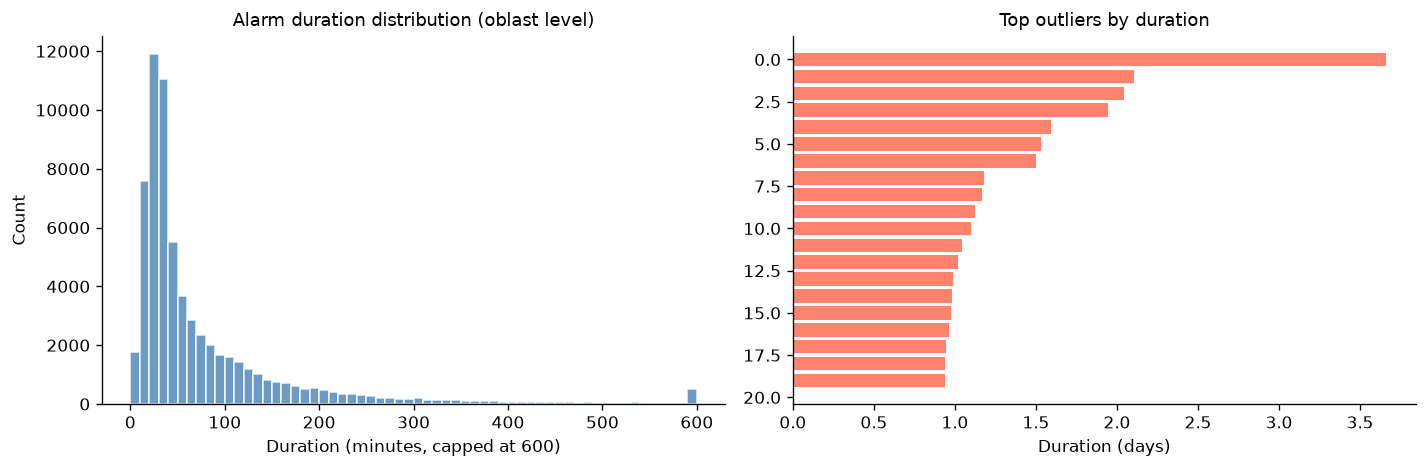

In [7]:
# Distribution plot — cap display at 600 min for readability
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

dur_capped = df['duration_min'].clip(upper=600)
axes[0].hist(dur_capped, bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_xlabel('Duration (minutes, capped at 600)')
axes[0].set_ylabel('Count')
axes[0].set_title('Alarm duration distribution (oblast level)', fontsize=11)

# Show the extreme tail to prove outliers exist
tail = df['duration_min'][df['duration_min'] > 500].sort_values(ascending=False)
axes[1].barh(range(min(20, len(tail))),
             tail.values[:20] / 60 / 24,  # convert to days
             color='tomato', alpha=0.8)
axes[1].set_xlabel('Duration (days)')
axes[1].set_title('Top outliers by duration', fontsize=11)
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [8]:
# Threshold: flag rows with duration > 24 hours as unreliable
# We keep them in df_clean (don't drop data unnecessarily) but flag them.
# For daily counts we only need started_at — the outlier duration does NOT affect counts.
DURATION_THRESHOLD_MIN = 24 * 60
df['duration_outlier'] = df['duration_min'] > DURATION_THRESHOLD_MIN

print(f'Flagged as duration outlier (>24h): {df["duration_outlier"].sum():,} rows')
print('\nSample outlier rows:')
df[df['duration_outlier']][['oblast', 'started_at', 'finished_at', 'duration_min']].head(5)

Flagged as duration outlier (>24h): 13 rows

Sample outlier rows:


,oblast,started_at,finished_at,duration_min
66,Chernihivska oblast,2022-03-16 08:08:41+02:00,2022-03-18 06:45:11+02:00,2796.500000
924,Luhanska oblast,2022-03-24 13:28:27+02:00,2022-03-28 06:22:00+03:00,5273.550000
1547,Chernihivska oblast,2022-03-30 20:47:14+03:00,2022-03-31 23:42:30+03:00,1615.266667
49408,Kharkivska oblast,2024-07-07 14:27:23+03:00,2024-07-09 03:15:08+03:00,2207.750000
50414,Kharkivska oblast,2024-07-20 08:47:05+03:00,2024-07-21 23:04:00+03:00,2296.916667


## Step 6 — Build daily counts

Group by calendar date in **Kyiv time**. This is the target series for `03_forecast.ipynb`.

In [9]:
df['date'] = df['started_at'].dt.date

daily_counts = (
    df.groupby('date')
    .size()
    .reset_index(name='n_alarms')
)
daily_counts['date'] = pd.to_datetime(daily_counts['date'])

print(f'Daily counts: {len(daily_counts)} days')
print(f'Range: {daily_counts["date"].min().date()}  →  {daily_counts["date"].max().date()}')
print(f'\nAlarms per day:')
print(daily_counts['n_alarms'].describe().round(1))
daily_counts.head()

Daily counts: 1491 days
Range: 2022-03-15  →  2026-06-23

Alarms per day:
count    1491.0
mean       43.7
std        25.9
min         1.0
25%        26.0
50%        45.0
75%        59.0
max       189.0
Name: n_alarms, dtype: float64


,date,n_alarms
0,2022-03-15,16
1,2022-03-16,47
2,2022-03-17,46
3,2022-03-18,49
4,2022-03-19,48


In [10]:
# Sanity check: missing days?
full_range = pd.date_range(daily_counts['date'].min(), daily_counts['date'].max(), freq='D')
missing_days = full_range.difference(daily_counts['date'])
print(f'Days in full range     : {len(full_range)}')
print(f'Days with data         : {len(daily_counts)}')
print(f'Missing days (0 alarms): {len(missing_days)}')
if len(missing_days) > 0:
    print(missing_days.tolist())

Days in full range     : 1562
Days with data         : 1491
Missing days (0 alarms): 71
[Timestamp('2025-04-20 00:00:00'), Timestamp('2025-11-12 00:00:00'), Timestamp('2025-11-21 00:00:00'), Timestamp('2025-11-22 00:00:00'), Timestamp('2025-11-23 00:00:00'), Timestamp('2025-11-26 00:00:00'), Timestamp('2025-11-30 00:00:00'), Timestamp('2025-12-01 00:00:00'), Timestamp('2025-12-02 00:00:00'), Timestamp('2025-12-04 00:00:00'), Timestamp('2025-12-08 00:00:00'), Timestamp('2025-12-09 00:00:00'), Timestamp('2025-12-12 00:00:00'), Timestamp('2025-12-14 00:00:00'), Timestamp('2025-12-15 00:00:00'), Timestamp('2025-12-17 00:00:00'), Timestamp('2025-12-18 00:00:00'), Timestamp('2025-12-19 00:00:00'), Timestamp('2025-12-20 00:00:00'), Timestamp('2025-12-21 00:00:00'), Timestamp('2025-12-22 00:00:00'), Timestamp('2025-12-24 00:00:00'), Timestamp('2025-12-28 00:00:00'), Timestamp('2025-12-29 00:00:00'), Timestamp('2025-12-30 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-01-07 00:00

## Step 7 — Save outputs

In [11]:
# Drop the duration column before saving (not needed downstream)
df_out = df.drop(columns=['duration_min', 'duration_outlier', 'date'])
df_out.to_csv('../data/clean.csv', index=False)
print('Saved: data/clean.csv')

daily_counts.to_csv('../data/daily_counts.csv', index=False)
print('Saved: data/daily_counts.csv')

Saved: data/clean.csv
Saved: data/daily_counts.csv


## Cleaning summary

| Step | Result |
|------|--------|
| Level filter | Only `level='oblast'` kept — eliminates triple-counting |
| Timezone | `started_at` / `finished_at` now in `Europe/Kyiv` |
| Exact duplicates | see output above |
| Duration outliers (>24h) | flagged — see output above; start times are reliable regardless |
| Missing days | see sanity check output |

→ Next: `03_forecast.ipynb` reads `daily_counts.csv` and builds baseline models.